In [2]:
from pyspark import SparkContext
from pyspark.sql import SparkSession

spark = SparkSession.builder.master("spark://spark-master:7077").getOrCreate()

authors_df = spark.read.json("hdfs://namenode:9000/goodreads_book_authors.json")
books_df = spark.read.json("hdfs://namenode:9000/goodreads_books_11k.json")
works_df = spark.read.json("hdfs://namenode:9000/goodreads_book_works.json")
genres_df = spark.read.json("hdfs://namenode:9000/goodreads_book_genres_initial_11k.json")

In [10]:
from pyspark.sql.functions import col, struct, lit, array, explode, when

# Lines of code in this box were generated by GenAI model:
# ChatGPT (GPT-5o), and Microsoft Copilot.

# Extract nested field names from the 'genres' struct
genre_fields = [f.name for f in genres_df.schema["genres"].dataType.fields]

# Build consistent (key, value) structs for every genre
genre_structs = [
    struct(lit(k).alias("key"), col(f"genres.`{k}`").alias("value")) for k in genre_fields
]

# Combine them into an array (now all have the same schema)
genres_array = array(*[
    when(col(f"genres.`{k}`") > 0, lit(k))  # only include if value > 0
    for k in genre_fields
])

# Add genres_array to the DataFrame
genres_df_with_array = genres_df.withColumn("genres_array", genres_array)

# Explode the array to rows of book_id and 1 genre
filtered_genres_df = genres_df_with_array.select(
    col("book_id"),
    explode(expr("filter(genres_array, x -> x IS NOT NULL)")).alias("genre")
)

# Show original genres
genres_df.show(10, truncate=False)
# View result
filtered_genres_df.show(10, truncate=False)


+--------+---------------------+
|book_id |genres               |
+--------+---------------------+
|5333265 |[,,,, 1,,,,,]        |
|1333909 |[,,, 219, 5,,,,,]    |
|7327624 |[,, 31, 8,, 1,, 1,,] |
|6066819 |[,,, 555,, 10,,, 23,]|
|287140  |[,,,,,, 3,,,]        |
|287141  |[6,, 1, 1, 9,,,,, 1] |
|378460  |[,,, 2,,,,,,]        |
|6066812 |[16,, 32, 7,,,,,, 8] |
|34883016|[,,,,,,,, 3,]        |
|287149  |[,,,, 1,, 24,,,]     |
+--------+---------------------+
only showing top 10 rows

+-------+--------------------------------------+
|book_id|genre                                 |
+-------+--------------------------------------+
|5333265|history, historical fiction, biography|
|1333909|fiction                               |
|1333909|history, historical fiction, biography|
|7327624|fantasy, paranormal                   |
|7327624|fiction                               |
|7327624|mystery, thriller, crime              |
|7327624|poetry                                |
|6066819|fiction      

In [15]:
# Drop unwanted columns from a DataFrame
books_df = books_df.drop("text_reviews_count", "description", "image_url", "link", "isbn13", "edition_information", "publisher", "country_code", "language_code", "kindle_asin", "asin", "similar_books", "url", "num_pages", "publication_month", "isbn", "series", "popular_shelves", "is_ebook", "format")
works_df = works_df.drop("text_reviews_count", "original_publication_month", "default_chaptering_book_id", "default_description_language_code", "original_publication_day", "original_language_id", "media_type")

In [17]:
from pyspark.sql.functions import explode, trim

# Clean columns
books_df = books_df.withColumn("author_id", explode(col("authors.author_id")))

# Convert ratings and review counts to numbers
books_df = books_df.withColumn(
                        "average_rating", 
                        when(trim(col("average_rating")) == "", 0)
                        .otherwise(col("average_rating").cast("double"))
                    ) \
                   .withColumn(
                        "ratings_count",
                        when(trim(col("ratings_count")) == "", 0)
                        .otherwise(col("ratings_count").cast("int"))
                    )

# Filter out works with no publication year recorded
works_df = works_df.filter(col("original_publication_year") != '')

# Convert ratings, review counts and publication year to numbers
works_df = works_df.withColumn(
                        "ratings_count",
                        when(trim(col("ratings_count")) == "", 0)
                        .otherwise(col("ratings_count").cast("int"))
                    ) \
                    .withColumn(
                        "original_publication_year",
                        when(trim(col("original_publication_year")) == "", 0)
                        .otherwise(col("original_publication_year").cast("int"))
                    )


Update data

In [24]:
from pyspark.sql.functions import col, when

# Update the first 2 authors to have average ratings of 5.0
updated_authors_df = authors_df.withColumn(
    "average_rating",
    when(col("author_id") == "604031", 5.0)
    .when(col("author_id") == "626222", 5.0)
    .otherwise(col("average_rating"))
)

# Write the updated data to HDFS as JSON
updated_authors_df.count()
updated_authors_df.write.mode("overwrite").json("hdfs://namenode:9000/updated_authors.json")

updated_authors_df.limit(10).show(truncate=False)

+---------+--------------+-------------------+-------------+------------------+
|author_id|average_rating|name               |ratings_count|text_reviews_count|
+---------+--------------+-------------------+-------------+------------------+
|604031   |5.0           |Ronald J. Fields   |49           |7                 |
|626222   |5.0           |Anita Diamant      |546796       |28716             |
|10333    |3.92          |Barbara Hambly     |122118       |5075              |
|9212     |3.68          |Jennifer Weiner    |888522       |36262             |
|149918   |3.82          |Nigel Pennick      |1740         |96                |
|3041852  |3.89          |Alfred J. Church   |947          |85                |
|215594   |4.17          |Michael Halberstam |23           |6                 |
|19158    |4.18          |Rachel Roberts     |13677        |486               |
|5807700  |3.99          |V.L. Locey         |3130         |986               |
|2983296  |3.48          |Anton Szandor 

In [13]:
# Show schema
authors_df.limit(10).show(truncate=False)
books_df.limit(15).show(truncate=False)
works_df.limit(10).show(truncate=False)
filtered_genres_df.limit(10).show(truncate=False)

+---------+--------------+-------------------+-------------+------------------+
|author_id|average_rating|name               |ratings_count|text_reviews_count|
+---------+--------------+-------------------+-------------+------------------+
|604031   |3.98          |Ronald J. Fields   |49           |7                 |
|626222   |4.08          |Anita Diamant      |546796       |28716             |
|10333    |3.92          |Barbara Hambly     |122118       |5075              |
|9212     |3.68          |Jennifer Weiner    |888522       |36262             |
|149918   |3.82          |Nigel Pennick      |1740         |96                |
|3041852  |3.89          |Alfred J. Church   |947          |85                |
|215594   |4.17          |Michael Halberstam |23           |6                 |
|19158    |4.18          |Rachel Roberts     |13677        |486               |
|5807700  |3.99          |V.L. Locey         |3130         |986               |
|2983296  |3.48          |Anton Szandor 

+-------+--------------------------------------+
|book_id|genre                                 |
+-------+--------------------------------------+
|5333265|history, historical fiction, biography|
|1333909|fiction                               |
|1333909|history, historical fiction, biography|
|7327624|fantasy, paranormal                   |
|7327624|fiction                               |
|7327624|mystery, thriller, crime              |
|7327624|poetry                                |
|6066819|fiction                               |
|6066819|mystery, thriller, crime              |
|6066819|romance                               |
+-------+--------------------------------------+



Top Genres by Average Rating and Ratings Count

+--------------------+-------------+------------------+
|               genre|total_ratings|        avg_rating|
+--------------------+-------------+------------------+
|              poetry|       123089| 3.964712230215828|
|         young-adult|      2051344|3.9131296449215505|
|             romance|      2392177|3.8962332990750292|
|         non-fiction|      1302875| 3.895547024952022|
| fantasy, paranormal|      2378171|3.8927870129870157|
|            children|       665394|3.8908384572386847|
|history, historic...|      1896239| 3.870977705527169|
|mystery, thriller...|      1904299| 3.869554102259212|
|     comics, graphic|       762756| 3.859155363748455|
|             fiction|      4353890|3.8549087292300563|
+--------------------+-------------+------------------+



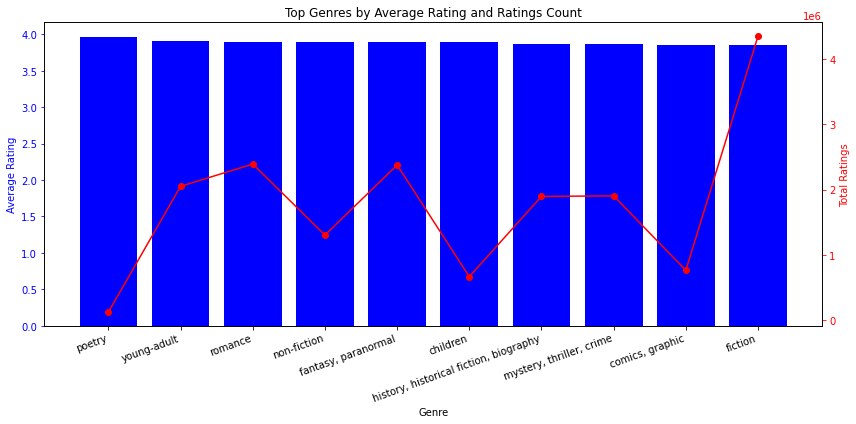

In [14]:
import matplotlib.pyplot as plt

books_df.createOrReplaceTempView("books_view")
filtered_genres_df.createOrReplaceTempView("genres_view")

result = spark.sql("""
    SELECT genre,
            SUM(b.ratings_count) AS total_ratings,
            AVG(b.average_rating) AS avg_rating
    FROM books_view b
    JOIN genres_view g ON b.book_id = g.book_id
    GROUP BY genre
    ORDER BY avg_rating DESC, total_ratings DESC
""")

result.show(10)

df = result.toPandas()

fig, ax1 = plt.subplots(figsize=(12,6))

# Plotting average rating on the primary y-axis
ax1.bar(df['genre'], df['avg_rating'], color='b', label='Average Rating')
ax1.set_xlabel('Genre')
ax1.set_ylabel('Average Rating', color='b')
ax1.set_xticks(range(len(df['genre'])))
ax1.tick_params('y', colors='b')
ax1.set_xticklabels(df['genre'], rotation=20, ha='right')

# Creating a second y-axis to plot total ratings (popularity)
ax2 = ax1.twinx()
ax2.plot(df['genre'], df['total_ratings'], color='r', marker='o', label='Total Ratings')
ax2.set_ylabel('Total Ratings', color='r')
ax2.tick_params('y', colors='r')

plt.title('Top Genres by Average Rating and Ratings Count')
fig.tight_layout()
plt.show()


Works Published and Popularity Across Decades

+------+-------------+------------------+---------+
|decade|total_ratings|        avg_rating|num_works|
+------+-------------+------------------+---------+
|  1960|       154953|3.8546863468634673|      197|
|  1970|        26569| 3.864917127071822|      277|
|  1980|       287307| 3.859574468085108|      486|
|  1990|       466888|3.8272006102212073|      928|
|  2000|      2259648| 3.797818077144497|     2354|
|  2010|      1485625|3.8954510761715677|     4589|
+------+-------------+------------------+---------+



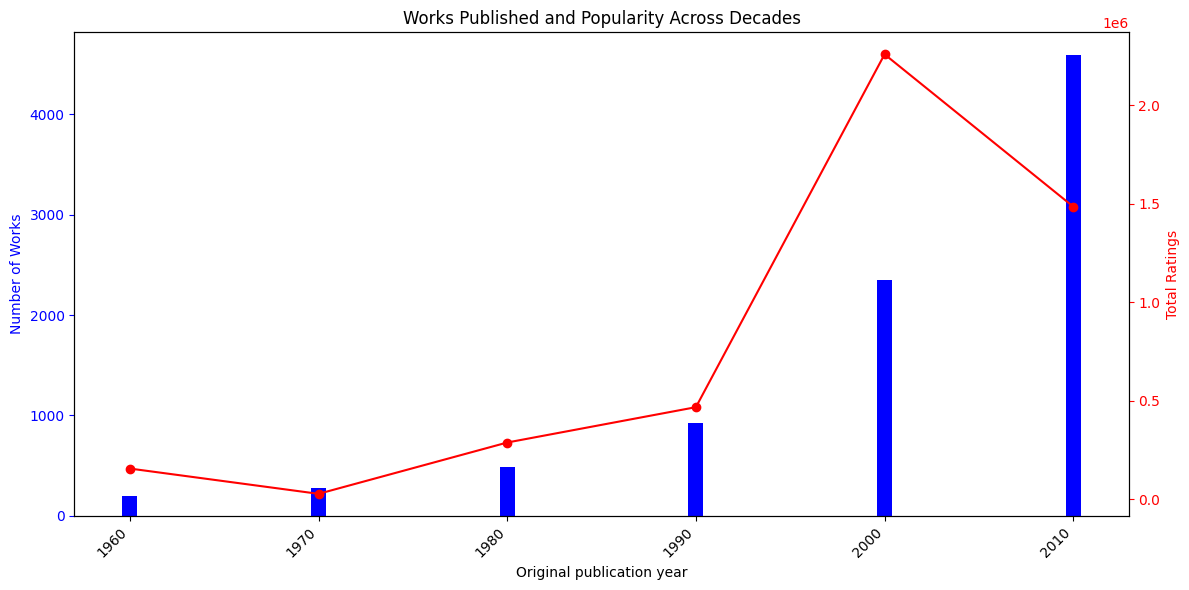

In [ ]:
works_df.createOrReplaceTempView("works_view")

result = spark.sql("""
    SELECT FLOOR(w.original_publication_year / 10) * 10 AS decade,
            SUM(b.ratings_count) AS total_ratings,
            AVG(b.average_rating) AS avg_rating,
            COUNT(DISTINCT w.work_id) AS num_works
    FROM works_view w
    JOIN books_view b ON w.work_id = b.work_id
    WHERE original_publication_year >= 1960
        AND w.original_publication_year <= 2025
    GROUP BY FLOOR(w.original_publication_year / 10) * 10
    ORDER BY decade ASC
""")

result.show(10)

df = result.toPandas()

plt.clf()
plt.close()

fig, ax3 = plt.subplots(figsize=(12,6))

# Plotting average rating on the primary y-axis
ax3.bar(df['decade'], df['num_works'], color='b', label='Number of Works')
ax3.set_xlabel('Original publication year')
ax3.set_ylabel('Number of Works', color='b')
ax3.set_xticks(df['decade'])
ax3.tick_params('y', colors='b')
ax3.set_xticklabels(df['decade'], rotation=45, ha='right')

# Creating a second y-axis to plot total ratings (popularity)
ax4 = ax3.twinx()
ax4.plot(df['decade'], df['total_ratings'], color='r', marker='o', label='Total Ratings')
ax4.set_ylabel('Total Ratings', color='r')
ax4.tick_params('y', colors='r')

plt.title('Works Published and Popularity Across Decades')
fig.tight_layout()
plt.show()

In [ ]:
pip install nbformat

Genre Frequency Across All Works (1990–2025)

In [13]:
result = spark.sql("""
    SELECT g.genre,
        COUNT(*) AS genre_count,
        FLOOR(w.original_publication_year / 10) * 10 AS decade
    FROM genres_view g
    JOIN books_view b ON g.book_id = b.book_id
    JOIN works_view w ON b.work_id = w.work_id
    WHERE w.original_publication_year >= 1990 AND w.original_publication_year <= 2025
    GROUP BY g.genre, FLOOR(w.original_publication_year / 10) * 10
    ORDER BY decade ASC, genre_count DESC
""")

result.show(20)

df = result.toPandas()

import plotly.express as px

fig = px.line(
    df,
    x='decade',
    y='genre_count',
    title='Genre Frequency Across All Works (1990–2025)',
    labels={'decade': 'Decade', 'genre_count': 'Number of Appearances'},
    color='genre',
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

+--------------------+-----------+------+
|               genre|genre_count|decade|
+--------------------+-----------+------+
|             fiction|        723|  1990|
|history, historic...|        478|  1990|
|         non-fiction|        474|  1990|
|mystery, thriller...|        283|  1990|
| fantasy, paranormal|        260|  1990|
|            children|        234|  1990|
|         young-adult|        222|  1990|
|             romance|        194|  1990|
|     comics, graphic|        127|  1990|
|              poetry|         71|  1990|
|             fiction|       2054|  2000|
|history, historic...|       1038|  2000|
|         non-fiction|        996|  2000|
| fantasy, paranormal|        901|  2000|
|mystery, thriller...|        889|  2000|
|             romance|        750|  2000|
|         young-adult|        587|  2000|
|            children|        501|  2000|
|     comics, graphic|        418|  2000|
|              poetry|        117|  2000|
+--------------------+-----------+

Top Popular Authors with Works in Fiction by Total Ratings Sum

In [12]:
authors_df.createOrReplaceTempView("authors_view")

result = spark.sql("""
    SELECT
        a.name AS author_name,
        SUM(w.ratings_sum) AS total_ratings_sum
    FROM authors_view a
    JOIN books_view b ON a.author_id = b.author_id
    JOIN works_view w ON b.work_id = w.work_id
    JOIN genres_view g ON b.book_id = g.book_id
    WHERE g.genre = 'fiction'
    GROUP BY a.name
    ORDER BY total_ratings_sum DESC
    LIMIT 10
""")

result.show()

df = result.toPandas()

fig = px.bar(
    df,
    x='author_name',
    y='total_ratings_sum',
    title='Top Popular Authors with Works in Fiction by Total Ratings Sum',
    labels={'author_name': 'Author', 'total_ratings_sum': 'Total Ratings Sum'},
    color='author_name'
)

fig.update_layout(xaxis_tickangle=-45)
fig.show()

+----------------+-----------------+
|     author_name|total_ratings_sum|
+----------------+-----------------+
|    J.K. Rowling|      6.1228601E7|
|  J.R.R. Tolkien|      3.3963631E7|
|     Jane Austen|      3.0078504E7|
|   George Orwell|      2.5850986E7|
|Lena Fries-Gedin|      2.2110592E7|
| Stephenie Meyer|      1.8410106E7|
|    Rick Riordan|      1.6281609E7|
| Khaled Hosseini|      1.5877752E7|
|Kathryn Stockett|      1.4598662E7|
|    Ryta Vinagre|      1.4264274E7|
+----------------+-----------------+

